*Adapted from code shared by David Gorkin (shared 9/29/25)*

# Calculate tau tissue-specificity indexes

# Settings

In [1]:
library(ggplot2)
library(dplyr)
library(patchwork)
library(gplots)
library(RColorBrewer)
library(grid)
library(gridExtra)
library(cowplot)
library(dplyr)
library(viridis)
library(tidyr)
library(dplyr)
library(reshape2)
library(here)
here::i_am("figures/Figure2/tau/characterize_gtex.ipynb")

set.seed(1234)
theme_set(theme_bw() + theme(panel.grid=element_blank()))

sessionInfo()

# quantile norm function
qn <- function(.data){
 data_sort <- apply(.data, 2, sort)
 row_means <- rowMeans(data_sort)
 data_sort <- matrix(row_means, 
                     nrow = nrow(data_sort), 
                     ncol = ncol(data_sort), 
                     byrow = TRUE
                     )
 index_rank <- apply(.data, 2, order)
 normalized_data <- matrix(nrow = nrow(.data), ncol = ncol(.data))
 for(i in 1:ncol(.data)){
   normalized_data[,i] <- data_sort[index_rank[,i], i]
 }
 return(normalized_data)
}



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘gplots’


The following object is masked from ‘package:stats’:

    lowess



Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine



Attaching package: ‘cowplot’


The following object is masked from ‘package:patchwork’:

    align_plots


Loading required package: viridisLite


Attaching package: ‘reshape2’


The following object is masked from ‘package:tidyr’:

    smiths


here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/Figure2/tau

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] grid      stats     graphics  grDevices utils     datasets  methods  
[8] base     

other attached packages:
 [1] here_1.0.2         reshape2_1.4.4     tidyr_1.3.1        viridis_0.6.5     
 [5] viridisLite_0.4.2  cowplot_1.1.3      gridExtra_2.3      RColorBrewer_1.1-3
 [9] gplots_3.2.0       patchwork_1.3.0    dplyr_1.1.4        ggplot2_3.5.2     

loaded via a namespace (and not atta

In [2]:
# input files

#gene metadata
rowdata <- readRDS(
  here("inputs", "GENCODE", "v47_rowdata_human.rds")
)

#GTEx tissue metadata
coldata <- readRDS(
  here("inputs", "GTEx", "coldata.rds")
)

#GTEx expression values (TPM)
exprmat <- readRDS(
  here("inputs", "GTEx", "exprmat.rds")
)

layout <- readRDS(
  here("inputs", "GTEx", "layout.rds")
)

# Filter unmeasured genes

In [3]:
print(paste0("N genes exprmat: ", nrow(exprmat)))
print(paste0("N genes rowdata: ", nrow(rowdata)))

any.na <- function(vals){
    return(any(is.na(vals)))}
temp.keep <- which(!apply(exprmat, MARGIN=1, FUN=any.na))
exprmat.filt <- exprmat[temp.keep,]
rowdata.filt <- rowdata[temp.keep,]
print(paste("N genes after filt NAs exprmat: ", nrow(exprmat.filt), sep=""))
print(paste("N genes after filt NAs rowdata: ", nrow(rowdata.filt), sep=""))

all.zero <- function(vals){
    return(all(vals==0))}
temp.keep <- which(!apply(exprmat.filt, MARGIN=1, FUN=all.zero))
exprmat.filt <- exprmat.filt[temp.keep,]
rowdata.filt <- rowdata.filt[temp.keep,]
print(paste("N genes after filt 0s exprmat: ", nrow(exprmat.filt), sep=""))
print(paste("N genes after filt 0s rowdata: ", nrow(rowdata.filt), sep=""))

[1] "N genes exprmat: 30696"
[1] "N genes rowdata: 30696"
[1] "N genes after filt NAs exprmat: 29702"
[1] "N genes after filt NAs rowdata: 29702"
[1] "N genes after filt 0s exprmat: 25696"
[1] "N genes after filt 0s rowdata: 25696"


In [4]:
#filter lowly expressed genes
temp.keep <- which(apply(exprmat.filt, MARGIN=1, FUN=function(x){ max(x) > 1}))
exprmat.filt <- exprmat.filt[temp.keep,]
rowdata.filt <- rowdata.filt[temp.keep,]
print(paste("N genes after filt max TPM <= 1 exprmat: ", nrow(exprmat.filt), sep=""))
print(paste("N genes after filt max TPM <= 1 rowdata: ", nrow(rowdata.filt), sep=""))

[1] "N genes after filt max TPM <= 1 exprmat: 22714"
[1] "N genes after filt max TPM <= 1 rowdata: 22714"


# explore expression distributions

In [5]:
#quantile normalize values
exprmat.filt.qnorm <- qn(exprmat.filt) %>% 
    `colnames<-`(colnames(exprmat.filt)) %>% 
    `rownames<-`(rownames(exprmat.filt))

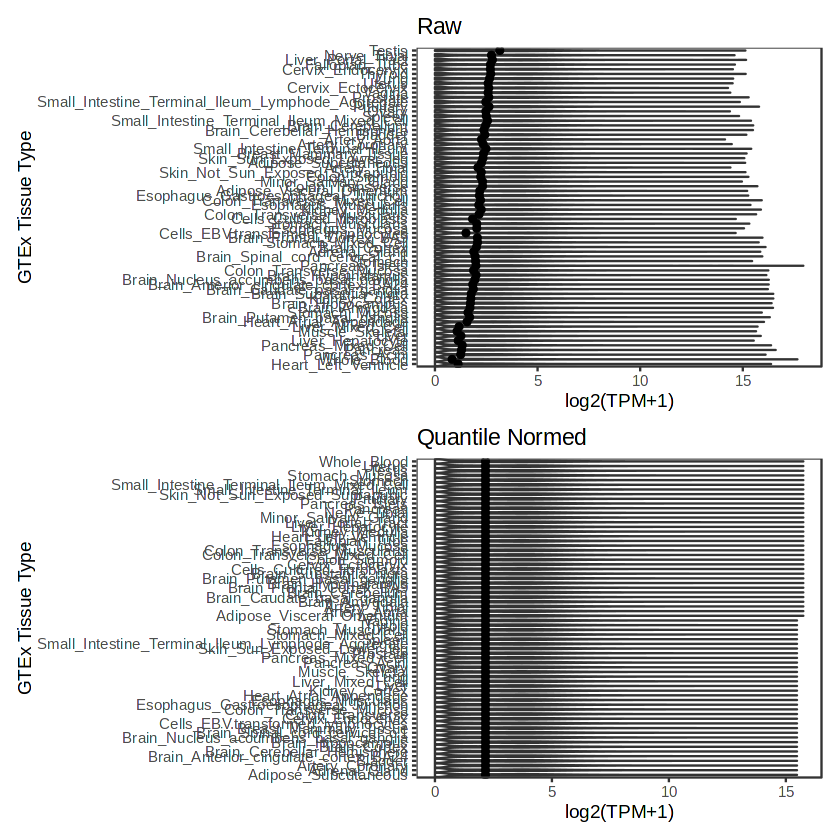

In [6]:
p1 <- exprmat.filt %>% 
        +1 %>% log2() %>% 
        data.frame() %>% 
        pivot_longer(everything()) %>%
        ggplot(aes(x=value, y=reorder(name,value))) + 
        theme_bw() + theme(panel.grid=element_blank()) + 
        geom_violin() +
        stat_summary(fun=median, geom="point") +
        xlab("log2(TPM+1)") + ylab("GTEx Tissue Type") + 
        ggtitle("Raw")

p2 <- exprmat.filt.qnorm %>% 
        +1 %>% log2() %>% 
        data.frame() %>% 
        pivot_longer(everything()) %>%
        ggplot(aes(x=value, y=reorder(name,value))) + 
        theme_bw() + theme(panel.grid=element_blank()) + 
        geom_violin() +
        stat_summary(fun=median, geom="point") +
        xlab("log2(TPM+1)") + ylab("GTEx Tissue Type") +
        ggtitle("Quantile Normed")

p1 / p2

# Calculate and plot tau

In [7]:
# function to calculate tau as in https://pubmed.ncbi.nlm.nih.gov/15388519/ & https://pubmed.ncbi.nlm.nih.gov/26891983/
calc.tau <- function(vals){
    return(sum(1-vals/max(vals))/(length(vals)-1))
}

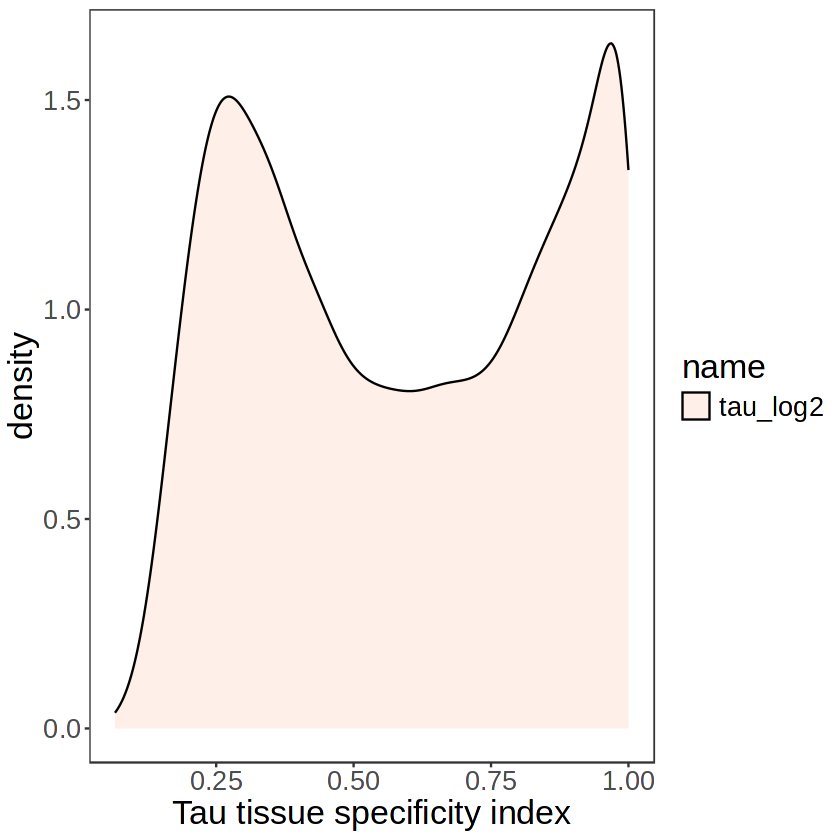

In [8]:
#calculate tau values using different normalization approaches
#log normalization
tau_log2 <- apply(log2(exprmat.filt+1), 1, calc.tau)

#make data frame
tau_df <- data.frame(gene_id_base=rowdata.filt$gene_id_base, gene_name=rowdata.filt$gene_name, tau_log2)

#evaluate tau index distribution
tau_df %>% select(!c(gene_name, gene_id_base)) %>% pivot_longer(cols=everything()) %>% ggplot(aes(x=value,fill=name)) + geom_density(linewidth=.5, alpha=.5) + 
    scale_fill_brewer(palette="Reds") + theme(text=element_text(size=20)) + xlab("Tau tissue specificity index")

In [9]:
#write out
write.table(tau_df, "GENCODE_GTex_Tau.tsv", sep='\t', row.names=FALSE)